# NekComp Compressible $Ma=1.25$ TGV at $Re=1600$

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import cantera as ct

In [14]:
plt.rcParams['font.size'] = '11'
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'

In [15]:
from cycler import cycler
new_cycler = (cycler(color=[[0, 0.4470, 0.7410], [0.8500, 0.3250, 0.0980], [0.9290, 0.6940, 0.1250], [0.4940, 0.1840, 0.5560], 
                            [0.4660, 0.6740, 0.1880], [0.3010, 0.7450, 0.9330], [0.6350, 0.0780, 0.1840], 'darkgreen']))
plt.rc('axes', prop_cycle=new_cycler)

In [16]:
str0 = "Ref"

### Solution from Galaexi

In [17]:
dir0 = "DATA_SUPERSONIC_TGV_POF/RE1600_M1.25/STATS/"

In [18]:
t0 = np.genfromtxt(dir0+"OpenSBLI_TENO6_N2048.dat", delimiter=' ', skip_header=1)

In [19]:
print(t0.shape)

(800, 4)


In [20]:
time0 = t0[:,0]
E0 = t0[:,1]
ens0 = t0[:,2]

### NekComp

In [21]:
a1 = ["E16N7","E32N7"]

In [22]:
cases1 = len(a1)
h1=np.zeros(cases1)
n1=np.zeros(cases1)
H1=[]
N1=[]
for i in range(cases1):
    h1[i]=float(a1[i][1:3])
    H1.append(r"$E=$"+str(int(h1[i]))+"$^3$")
    n1[i]=int(a1[i][4:5])
    N1.append(r"$N=$"+str(int(n1[i])))

In [23]:
time1 = []
E1 = []
ens1 = []

In [24]:
for i in range(cases1):
    t1 = np.genfromtxt(a1[i]+"_Ma125.dat", delimiter='  ')
    time1.append(t1[:,0])
    E1.append(t1[:,1])
    ens1.append(t1[:,2])

### Comparison plots

In [25]:
tmin = 0
tmax = 20

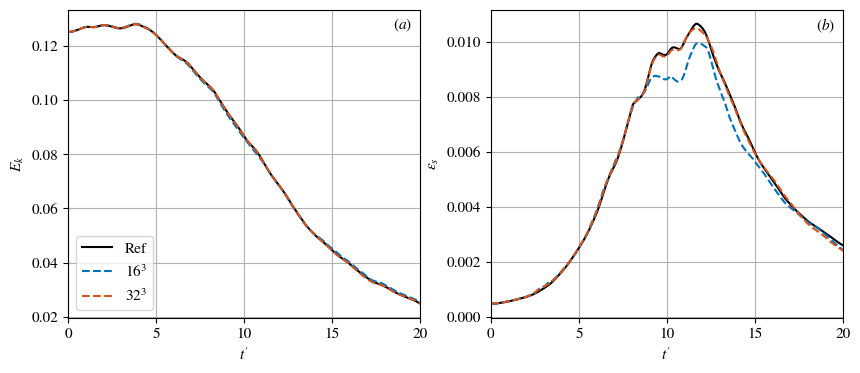

In [26]:
fig,ax = plt.subplots(1,2,figsize=(10,4))
lbls=[r"$(a)$",r"$(b)$",r"$(c)$",r"$(d)$"]

ix=0
ax[ix].set_xlim(tmin,tmax)
ax[ix].set_xlabel(r"$t'$ ")
ax[ix].set_ylabel(r"$E_k$")
ax[ix].grid()
ax[ix].plot(time0,E0,color='black',label=str0)
for i in range(cases1):
    ax[ix].plot(time1[i],E1[i],linestyle='--',label=str(int(h1[i]))+r"$^3$")
ax[ix].legend(loc=3);
ax[ix].text(.95,.95,lbls[0],horizontalalignment='center',verticalalignment='center',transform = ax[ix].transAxes)

ix=1
ax[ix].set_xlim(tmin,tmax)
ax[ix].set_xlabel(r"$t'$ ")
# ax[ix].set_ylabel(r"$\omega \cdot \omega$")
ax[ix].set_ylabel(r"$\varepsilon_s$")
ax[ix].grid()
ax[ix].plot(time0,ens0,color='black',label=str0)
for i in range(cases1):
    ax[ix].plot(time1[i],ens1[i],linestyle='--',label=str(int(h1[i]))+r"$^3$")
#ax[ix].legend(loc=2);
ax[ix].text(.95,.95,lbls[1],horizontalalignment='center',verticalalignment='center',transform = ax[ix].transAxes)

fig.savefig("images/tgvComp.png", bbox_inches="tight", dpi = 300)

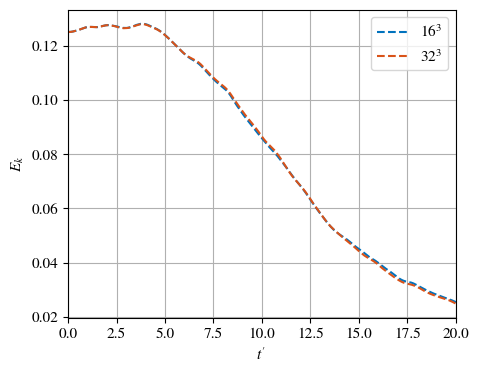

In [27]:
fig,ax = plt.subplots(figsize=(5,4))
ix=1
ax.set_xlim(tmin,tmax)
# ax.set_ylim(0,0.015)
ax.set_xlabel(r"$t'$ ")
ax.set_ylabel(r"$E_k$")
ax.grid()
for i in range(cases1):
    ax.plot(time1[i],E1[i],linestyle='--',label=str(int(h1[i]))+r"$^3$")
ax.legend(loc='best');
fig.savefig("images/tgvComp1.png", bbox_inches="tight", dpi = 300)

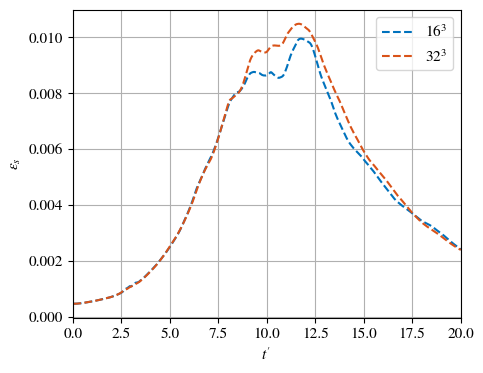

In [28]:
fig,ax = plt.subplots(figsize=(5,4))
ix=1
ax.set_xlim(tmin,tmax)
# ax.set_ylim(0,0.015)
ax.set_xlabel(r"$t'$ ")
ax.set_ylabel(r"$\varepsilon_s$")
ax.grid()
for i in range(cases1):
    ax.plot(time1[i],ens1[i],linestyle='--',label=str(int(h1[i]))+r"$^3$")
ax.legend(loc='best');
fig.savefig("images/tgvComp2.png", bbox_inches="tight", dpi = 300)